# Первичный анализ набора данных
**Датасет:** Predict Students' Dropout and Academic Success (Kaggle).
**Задача:** бинарная классификация — отчислится студент (Dropout) или продолжит обучение (Enrolled / Graduate).


## 1 Загрузка данных и библиотек

In [ ]:
import numpy as np  # численные вычисления и массивы
import pandas as pd  # работа с табличными данными (DataFrame)
import matplotlib.pyplot as plt  # построение графиков

In [2]:
df = pd.read_csv("dataset.csv", encoding="utf-8-sig")  # utf-8-sig убирает BOM в имени первого столбца
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 2 Общая информация

In [3]:
df.shape  # размер датасета: (число строк, число столбцов)

(4424, 35)

In [4]:
df.columns  # список названий всех столбцов

Index(['Marital status', 'Application mode', 'Application order', 'Course',
       'Daytime/evening attendance', 'Previous qualification', 'Nacionality',
       'Mother's qualification', 'Father's qualification',
       'Mother's occupation', 'Father's occupation', 'Displaced',
       'Educational special needs', 'Debtor', 'Tuition fees up to date',
       'Gender', 'Scholarship holder', 'Age at enrollment', 'International',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd sem (grade)',
       'Curricular units 2nd sem (without evaluations)

In [5]:
df.info()  # типы данных столбцов, число непустых значений и объём памяти

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Nacionality                                     4424 non-null   int64  
 7   Mother's qualification                          4424 non-null   int64  
 8   Father's qualification                          4424 non-null   int64  
 9   Mother's occupation                             4424

In [6]:
df.describe().T  # среднее, медиана, квартили, минимум и максимум по числовым столбцам

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,6.886980,5.298964,1.00,1.00,8.000000,12.000000,18.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,9.899186,4.331792,1.00,6.00,10.000000,13.000000,17.000000
Daytime/evening attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,2.531420,3.963707,1.00,1.00,1.000000,1.000000,17.000000
Nacionality,4424.0,1.254521,1.748447,1.00,1.00,1.000000,1.000000,21.000000
Mother's qualification,4424.0,12.322107,9.026251,1.00,2.00,13.000000,22.000000,29.000000
Father's qualification,4424.0,16.455244,11.044800,1.00,3.00,14.000000,27.000000,34.000000
Mother's occupation,4424.0,7.317812,3.997828,1.00,5.00,6.000000,10.000000,32.000000


## 3 Пропущенные значения

In [7]:
df.isna().sum()  # количество пропусков по столбцам

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrollment                                 0
International                                     0
Curricular u

In [8]:
(df.isna().mean() * 100).round(2).sum()  # суммарная доля пропусков в процентах

np.float64(0.0)

In [9]:
# Проверяем и «скрытые» пропуски: пустые строки и пробелы в текстовых столбцах
(df.select_dtypes(exclude="number").apply(lambda s: s.str.strip().eq("")).sum())

Target    0
dtype: int64

## 4 Дубликаты

In [10]:
df.duplicated().sum()  # число полных копий сверх первого вхождения

np.int64(0)

In [11]:
# df[df.duplicated(keep=False)].head(10)  # примеры, включая первые вхождения

## 5 Уникальные значения и константные признаки

In [12]:
df.nunique()  # число уникальных непустых значений каждого столбца

Marital status                                      6
Application mode                                   18
Application order                                   8
Course                                             17
Daytime/evening attendance                          2
Previous qualification                             17
Nacionality                                        21
Mother's qualification                             29
Father's qualification                             34
Mother's occupation                                32
Father's occupation                                46
Displaced                                           2
Educational special needs                           2
Debtor                                              2
Tuition fees up to date                             2
Gender                                              2
Scholarship holder                                  2
Age at enrollment                                  46
International               

In [13]:
unique_counts = df.nunique()
unique_counts[unique_counts <= 1]  # столбцы с одним значением или без значений

Series([], dtype: int64)

Многие столбцы хранятся как целые числа, но по смыслу являются категориальными (коды): например, `Course`, `Application mode`, `Mother's occupation`. Отделим их от настоящих количественных признаков по числу уникальных значений и смыслу.

In [14]:
# Делим признаки на группы по смыслу:
binary_cols = [c for c in df.columns if df[c].nunique() == 2 and c != "Target"]  # бинарные: ровно 2 значения (0/1)
coded_cols = ["Marital status", "Application mode", "Application order", "Course", "Previous qualification",
              "Nacionality", "Mother's qualification", "Father's qualification",
              "Mother's occupation", "Father's occupation"]  # категории, закодированные числами (код ≠ величина)
numeric_cols = [c for c in df.columns if c not in binary_cols + coded_cols + ["Target"]]  # остальное — количественные

print("Бинарные (0/1):", len(binary_cols), binary_cols)
print("Категориальные коды:", len(coded_cols))
print("Количественные:", len(numeric_cols), numeric_cols)

Бинарные (0/1): 8 ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']
Категориальные коды: 10
Количественные: 16 ['Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP']


## 6 Баланс классов

In [15]:
df["Target"].value_counts(dropna=False)  # количество объектов, включая пропуски

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

In [16]:
(df["Target"].value_counts(normalize=True) * 100).round(2)  # доли среди строк с известной меткой

Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64

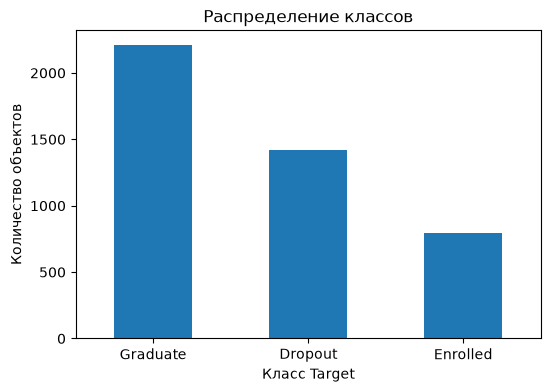

In [17]:
df["Target"].value_counts().plot(kind="bar", figsize=(6, 4))  # столбчатая диаграмма числа объектов в каждом классе
plt.title("Распределение классов")
plt.xlabel("Класс Target")
plt.ylabel("Количество объектов")
plt.xticks(rotation=0)  # подписи классов горизонтально
plt.show()

По постановке задачи (Этап 1) целевая переменная сводится к бинарной: **1 — Dropout**, **0 — Enrolled или Graduate**.

In [18]:
df["Dropout"] = (df["Target"] == "Dropout").astype(int)  # бинарная метка: 1 — отчислен, 0 — нет
(df["Dropout"].value_counts(normalize=True) * 100).round(2)  # доли классов в процентах — видно дисбаланс

Dropout
0    67.88
1    32.12
Name: proportion, dtype: float64

## 7 Распределения числовых признаков

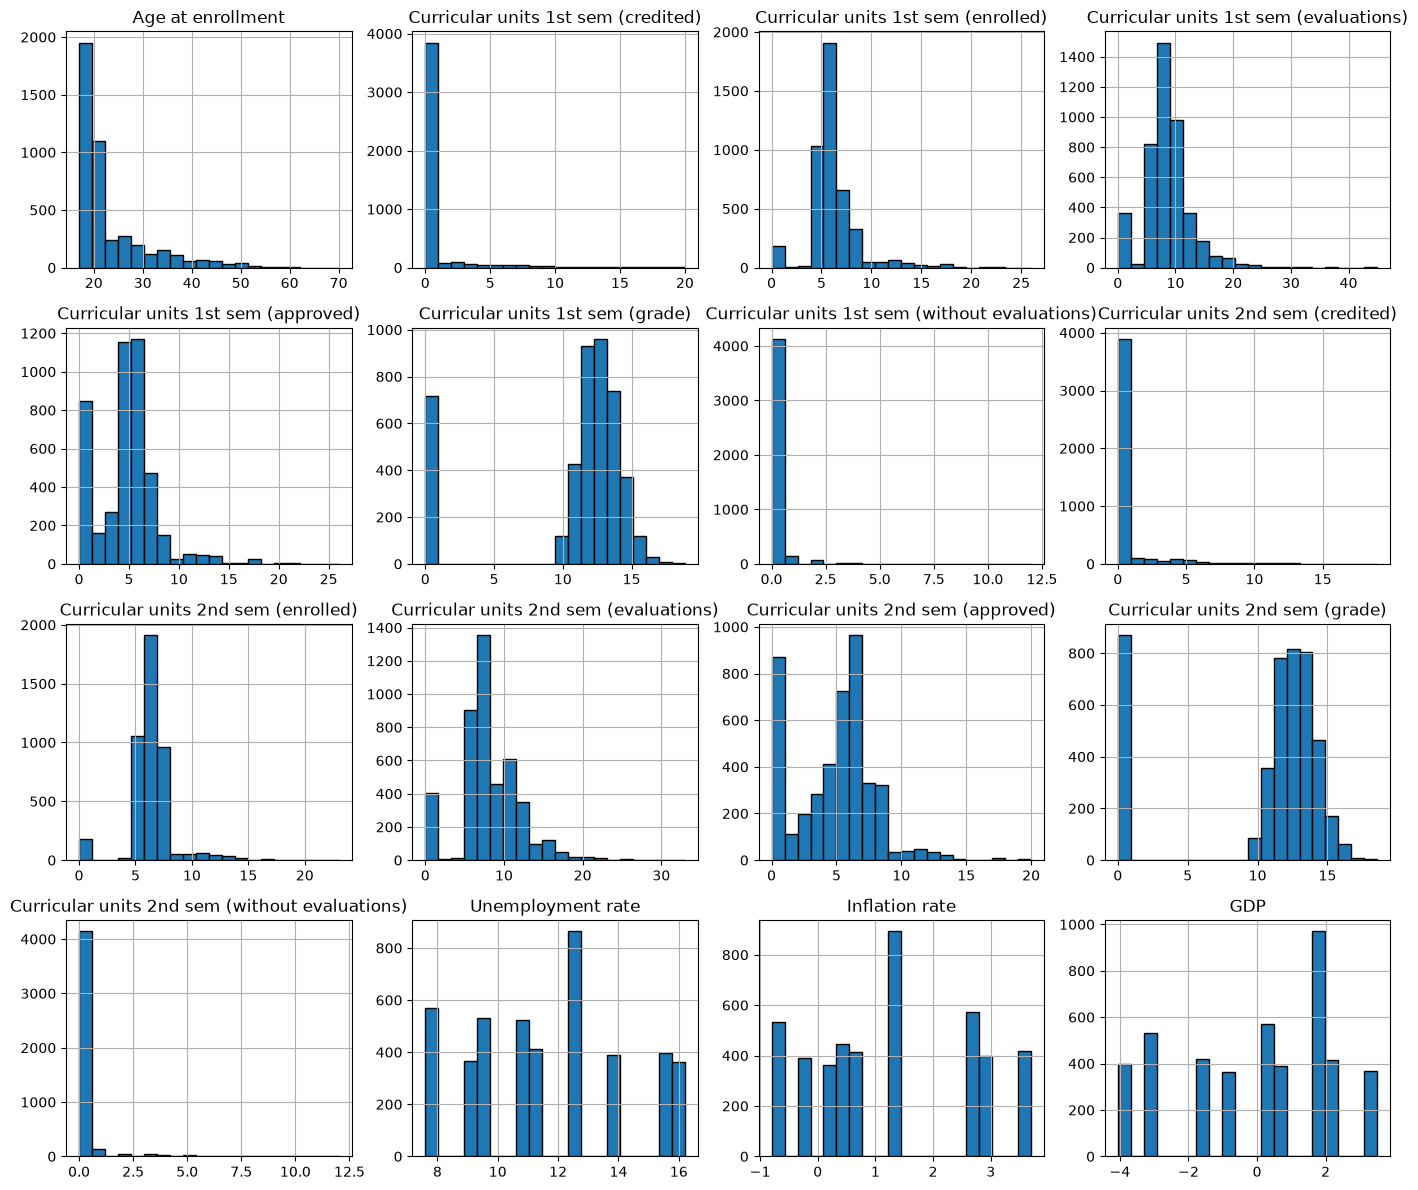

In [19]:
df[numeric_cols].hist(bins=20, figsize=(14, 12), edgecolor="black")  # гистограммы распределений количественных признаков
plt.tight_layout()  # чтобы подписи графиков не наезжали друг на друга
plt.show()

Видно, что показатели по дисциплинам (`credited`, `without evaluations`) сосредоточены около нуля, а у `grade` есть отдельный пик в нуле — это студенты без единой оценки за семестр. Возраст при поступлении скошен вправо: большинство 18–22 лет, но есть «хвост» до 70.

## 8 Boxplot одного признака
Для другого признака достаточно изменить значение `column`.

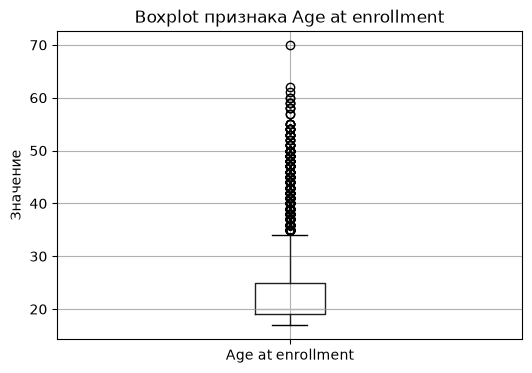

In [20]:
column = "Age at enrollment"  # признак для boxplot — возраст при поступлении
df.boxplot(column=column, figsize=(6, 4))  # «ящик с усами»: медиана, квартили и выбросы
plt.title(f"Boxplot признака {column}")
plt.ylabel("Значение")
plt.show()

Линия внутри ящика — медиана, ящик охватывает центральные 50% значений. Отдельные точки за усами — потенциальные выбросы. Здесь выбросы по возрасту — не ошибки, а реальные взрослые студенты (в основном вечерняя форма), удалять их не нужно.

## 9 Связь признаков с целевой переменной

In [21]:
# Доля отчислений в разрезе нескольких бинарных признаков
for col in ["Debtor", "Tuition fees up to date", "Scholarship holder", "Gender", "Daytime/evening attendance"]:
    print((df.groupby(col)["Dropout"].mean() * 100).round(1).rename("Доля отчислений, %").to_string(), "\n")

Debtor
0    28.3
1    62.0 

Tuition fees up to date
0    86.6
1    24.7 

Scholarship holder
0    38.7
1    12.2 

Gender
0    25.1
1    45.1 

Daytime/evening attendance
0    42.9
1    30.8 



In [22]:
# Средний балл за 1-й семестр по классам
df.groupby("Target")["Curricular units 1st sem (grade)"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Target,,,,,,,,
Dropout,1421.0,7.26,6.03,0.0,0.00,10.93,12.20,18.00
Enrolled,794.0,11.13,3.68,0.0,11.00,12.00,12.86,17.00
Graduate,2209.0,12.64,2.70,0.0,12.12,13.00,13.86,18.88


## 10 Краткий итог аудита

In [23]:
# Краткая сводка по итогам обзора датасета
print("Количество строк:", len(df))
print("Количество столбцов:", len(df.columns) - 1, "(без добавленного Dropout)")
print("Пропущенных ячеек:", df.isna().sum().sum())
print("Полных копий:", df.duplicated().sum())
print("Доля класса Dropout, %:", round(df["Dropout"].mean() * 100, 1))

Количество строк: 4424
Количество столбцов: 35 (без добавленного Dropout)
Пропущенных ячеек: 0
Полных копий: 0
Доля класса Dropout, %: 32.1


**Выводы аудита**
- Данные чистые: пропусков и дубликатов нет, константных столбцов нет.
- В этой Kaggle-версии 34 признака + Target (в оригинале на UCI 36 — нет столбцов «Previous qualification (grade)» и «Admission grade»).
- 10 столбцов — категориальные коды, записанные числами; перед моделированием их нужно перекодировать (one-hot), а не использовать как числа.
- Классы несбалансированы умеренно: Dropout ≈ 32%.
- Выбросы по возрасту — реальные наблюдения, не ошибки.
- Должники, неплательщики и студенты без стипендии отчисляются заметно чаще; у отчисленных средний балл за 1-й семестр существенно ниже.


## 11 Предобработка данных

In [24]:
# df = df.fillna(df.median(numeric_only=True))  # пропусков нет — не требуется
# df = df.drop_duplicates()                      # дубликатов нет — не требуется

# 1) Исправляем опечатку в названии столбца из исходного файла
df = df.rename(columns={"Nacionality": "Nationality"})

# 2) Перекодируем категориальные коды в one-hot признаки
coded_cols = [c if c != "Nacionality" else "Nationality" for c in coded_cols]
df_prep = pd.get_dummies(df.drop(columns=["Target"]), columns=coded_cols, drop_first=True)

print("Форма после предобработки:", df_prep.shape)
df_prep.head()

Форма после предобработки: (4424, 243)


,Daytime/evening attendance,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),...,Father's occupation_37,Father's occupation_38,Father's occupation_39,Father's occupation_40,Father's occupation_41,Father's occupation_42,Father's occupation_43,Father's occupation_44,Father's occupation_45,Father's occupation_46
0,1,1,0,0,1,1,0,20,0,0,...,False,False,False,False,False,False,False,False,False,False
1,1,1,0,0,0,1,0,19,0,0,...,False,False,False,False,False,False,False,False,False,False
2,1,1,0,0,0,1,0,19,0,0,...,False,False,False,False,False,False,False,False,False,False
3,1,1,0,0,1,0,0,20,0,0,...,False,False,False,False,False,False,False,False,False,False
4,0,0,0,0,1,0,0,45,0,0,...,False,False,False,False,False,False,False,False,False,False
